In [5]:
"""
Publication-style figure: Precision@k, Recall@k, nDCG@k, HR@k for the
GHCF-R / GHCF-A / GHCF-ACE / GHCF-CE comparison (norm-adjacency GCN backbone,
mse loss), one row of 4 subplots, sized and styled for a research-paper figure.

GHCF-R   = RATING-only baseline           (single_none_mse_norm_gcn)
GHCF-A   = all-relations baseline         (default_none_mse_norm_gcn)
GHCF-ACE = all-relations + ACE blend      (default_ace_learnable_fs0_mse_norm_gcn)
GHCF-CE  = all-relations + causal SEM head (default_causal_fs0_mse_norm_gcn)

Source: checkpoints/sweep_20260908_111421 (per-fold causal discovery,
99/99 ok).

Run:
    python plot_chain_metrics.py
Output:
    recommendation_metrics.png   (and .pdf for LaTeX \includegraphics)
"""

import matplotlib.pyplot as plt
import matplotlib as mpl

plt.style.use("default")  # default qualitative colormap for lines
# ---------------------------------------------------------------------------
# Data (norm-adjacency GCN backbone, mse loss; GHCF-R / GHCF-A / GHCF-ACE /
# GHCF-CE) -- sweep_20260908_111421, mean over 5 CV folds
# ---------------------------------------------------------------------------
ks = [3, 5, 10]

data = {
    "GHCF-R": {  # single_none_mse_norm_gcn (RATING only)
        "precision": [0.423810, 0.404762, 0.401429],
        "recall": [0.127800, 0.193372, 0.332242],
        "ndcg": [0.699895, 0.737785, 0.731488],
        "hit": [0.842857, 0.938095, 0.971429],
    },
    "GHCF-A": {  # default_none_mse_norm_gcn (all relations, no causal head)
        "precision": [0.425397, 0.420000, 0.410476],
        "recall": [0.127235, 0.190303, 0.347158],
        "ndcg": [0.621596, 0.679769, 0.692363],
        "hit": [0.819048, 0.938095, 1.0],
    },
    # "GHCF-ACE": {  # default_ace_learnable_fs0_mse_norm_gcn
    #     "precision": [0.449206, 0.463810, 0.491429],
    #     "recall":    [0.115314, 0.184160, 0.338610],
    #     "ndcg":      [0.649931, 0.710111, 0.731221],
    #     "hit":       [0.847619, 0.971429, 1.0],
    # },
    "GHCF-CE": {  # default_causal_fs0_mse_norm_gcn
        "precision": [0.515873, 0.505714, 0.489048],
        "recall": [0.128468, 0.191615, 0.327999],
        "ndcg": [0.769033, 0.758951, 0.779417],
        "hit": [0.938095, 0.938095, 1.0],
    },
}

# models_order = ["GHCF-R", "GHCF-A", "GHCF-ACE", "GHCF-CE"]
models_order = ["GHCF-R", "GHCF-A", "GHCF-CE"]  # skip ACE for now
metrics = ["precision", "recall", "ndcg", "hit"]
metric_titles = {
    "precision": "Precision@$k$",
    "recall": "Recall@$k$",
    "ndcg": "nDCG@$k$",
    "hit": "HR@$k$",
}
model_colors = {
    "GHCF-R": "#1f77b4",
    "GHCF-A": "#9467bd",
    # "GHCF-ACE": "#ff7f0e",
    "GHCF-CE": "#2ca02c",
}
model_markers = {
    "GHCF-R": "o",
    "GHCF-A": "D",
    # "GHCF-ACE": "s",
    "GHCF-CE": "^",
}

# ---------------------------------------------------------------------------
# Paper-style rcParams: larger fonts, serif face, clean axes
# ---------------------------------------------------------------------------
mpl.rcParams.update(
    {
        "font.size": 16,
        "font.family": "serif",
        "axes.titlesize": 18,
        "axes.labelsize": 17,
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
        "legend.fontsize": 16,
        "axes.linewidth": 1.2,
        "lines.linewidth": 2.6,
        "lines.markersize": 10,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "grid.linewidth": 0.6,
    }
)

fig, axes = plt.subplots(1, 4, figsize=(22, 5.2))

for ax, metric in zip(axes, metrics):
    for model in models_order:
        ax.plot(
            ks,
            data[model][metric],
            label=model,
            color=model_colors[model],
            marker=model_markers[model],
            markeredgecolor="white",
            markeredgewidth=1.0,
        )
    ax.set_title(metric_titles[metric], pad=12)
    ax.set_xlabel("$k$")
    ax.set_xticks(ks)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(width=1.2, length=6)

axes[0].set_ylabel("Value")

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=len(models_order),
    bbox_to_anchor=(0.5, 1.12),
    frameon=False,
    handlelength=2.2,
    columnspacing=2.0,
)

fig.tight_layout()

fig.savefig("recommendation_metrics.png", dpi=300, bbox_inches="tight")
fig.savefig("recommendation_metrics.pdf", bbox_inches="tight")
plt.close(fig)
print("saved recommendation_metrics.png / .pdf")

saved recommendation_metrics.png / .pdf


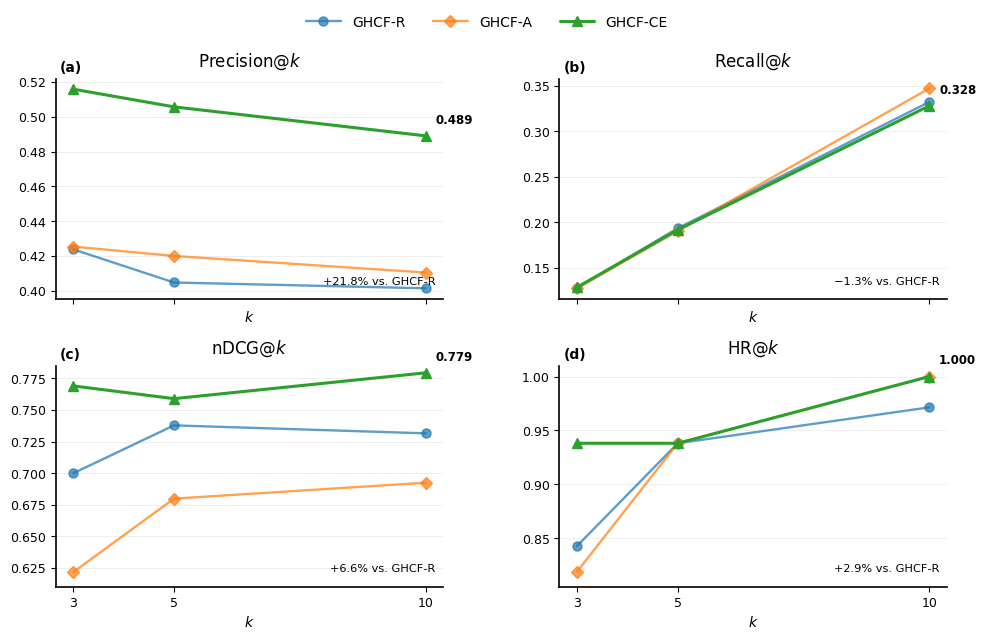

PNG: recommendation_metrics.png
PDF: recommendation_metrics.pdf
SVG: recommendation_metrics.svg


In [13]:
import matplotlib.pyplot as plt
from pathlib import Path

# -----------------------------
# Data
# -----------------------------
k = [3, 5, 10]

data = {
    "GHCF-R": {
        "precision": [0.423810, 0.404762, 0.401429],
        "recall": [0.127800, 0.193372, 0.332242],
        "ndcg": [0.699895, 0.737785, 0.731488],
        "hit": [0.842857, 0.938095, 0.971429],
    },
    "GHCF-A": {
        "precision": [0.425397, 0.420000, 0.410476],
        "recall": [0.127235, 0.190303, 0.347158],
        "ndcg": [0.621596, 0.679769, 0.692363],
        "hit": [0.819048, 0.938095, 1.000000],
    },
    "GHCF-CE": {
        "precision": [0.515873, 0.505714, 0.489048],
        "recall": [0.128468, 0.191615, 0.327999],
        "ndcg": [0.769033, 0.758951, 0.779417],
        "hit": [0.938095, 0.938095, 1.000000],
    },
}

metrics = [
    ("precision", r"Precision@$k$"),
    ("recall", r"Recall@$k$"),
    ("ndcg", r"nDCG@$k$"),
    ("hit", r"HR@$k$"),
]

# Publication-friendly defaults
plt.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 12,
        "axes.labelsize": 10,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "legend.fontsize": 10,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

# -----------------------------
# Figure
# -----------------------------
fig, axes = plt.subplots(
    2,
    2,
    figsize=(11.5, 6.6),
    sharex=True,
    constrained_layout=False,
)
plt.subplots_adjust(hspace=0.3, wspace=0.3)

# Keep method identity consistent.
styles = {
    "GHCF-R": {"marker": "o", "linewidth": 1.7, "alpha": 0.72},
    "GHCF-A": {"marker": "D", "linewidth": 1.7, "alpha": 0.72},
    "GHCF-CE": {"marker": "^", "linewidth": 2.2, "alpha": 1.00},
}

# Tight but readable metric-specific limits.
ylims = {
    "precision": (0.395, 0.522),
    "recall": (0.115, 0.358),
    "ndcg": (0.610, 0.785),
    "hit": (0.805, 1.010),
}

# Δ relative to GHCF-R at k=10.
delta = {}
for metric, _ in metrics:
    r = data["GHCF-R"][metric][-1]
    ce = data["GHCF-CE"][metric][-1]
    delta[metric] = (ce - r) / r * 100

for ax, (metric, title) in zip(axes.flat, metrics):
    for method, values in data.items():
        s = styles[method]
        ax.plot(
            k,
            values[metric],
            marker=s["marker"],
            markersize=6.5 if method != "GHCF-CE" else 7.5,
            linewidth=s["linewidth"],
            alpha=s["alpha"],
            label=method,
            solid_capstyle="round",
        )

    ax.set_title(title, pad=9)
    ax.set_ylim(*ylims[metric])
    ax.set_xticks(k)
    ax.set_xlabel(r"$k$", labelpad=4)
    ax.grid(axis="y", linewidth=0.6, alpha=0.25)
    ax.grid(axis="x", visible=False)
    ax.tick_params(length=3.5)

    # Highlight the GHCF-CE endpoint at k=10.
    ce10 = data["GHCF-CE"][metric][-1]
    ax.annotate(
        f"{ce10:.3f}",
        xy=(10, ce10),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=8.5,
        fontweight="bold",
        ha="left",
        va="bottom",
    )

    # Compact relative-improvement annotation.
    sign = "+" if delta[metric] >= 0 else "−"
    ax.text(
        0.98,
        0.06,
        f"{sign}{abs(delta[metric]):.1f}% vs. GHCF-R",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
        fontsize=8.2,
    )

# Panel labels
for ax, label in zip(axes.flat, ["(a)", "(b)", "(c)", "(d)"]):
    ax.text(
        0.01,
        1.02,
        label,
        transform=ax.transAxes,
        fontsize=10,
        fontweight="bold",
        va="bottom",
    )

# Shared legend.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.5, 0.995),
    handlelength=2.5,
    columnspacing=2.0,
)

# # Figure-level interpretation.
# fig.text(
#     0.5, 0.015,
#     "Higher is better. GHCF-CE improves precision and ranking quality while maintaining a near-perfect hit rate.",
#     ha="center",
#     va="bottom",
#     fontsize=9,
# )

# fig.subplots_adjust(
#     left=0.065,
#     right=0.985,
#     bottom=0.105,
#     top=0.86,
#     wspace=0.20,
#     hspace=0.32,
# )

# -----------------------------
# Export
# -----------------------------
out_dir = Path("./")
png_path = out_dir / "recommendation_metrics.png"
pdf_path = out_dir / "recommendation_metrics.pdf"
svg_path = out_dir / "recommendation_metrics.svg"

fig.savefig(png_path, dpi=400, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")
fig.savefig(svg_path, bbox_inches="tight")
plt.show()

print(f"PNG: {png_path}")
print(f"PDF: {pdf_path}")
print(f"SVG: {svg_path}")